1. Load the dataset

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/spam.csv', encoding='latin-1')

# Display first five rows
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


2. Understand the dataset

In [25]:
# Dataset size
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nDataset Description:")
df.describe(include='all')

Dataset Shape: (5572, 5)

Column Names:
Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB

Dataset Description:


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
count,5572,5572,50,12,6
unique,2,5169,43,10,5
top,ham,"Sorry, I'll call later","bt not his girlfrnd... G o o d n i g h t . . .@""","MK17 92H. 450Ppw 16""","GNT:-)"""
freq,4825,30,3,2,2


3. Clean the dataset

In [26]:
# Keep only required columns
df = df[['v1', 'v2']]

# Rename columns
df.columns = ['label', 'message']

# Display cleaned dataset
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


4. Check the dataset

In [17]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:")
print(df.duplicated().sum())

Dataset Shape: (5572, 2)

Missing Values:
label      0
message    0
dtype: int64

Duplicate Values:
403


5. Remove duplicate messages

In [27]:
# Check duplicates before removal
print("Duplicates before cleaning:", df.duplicated().sum())

# Remove duplicate messages
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

# Check after removal
print("Duplicates after cleaning:", df.duplicated().sum())

print("Final Dataset Shape:", df.shape)

Duplicates before cleaning: 403
Duplicates after cleaning: 0
Final Dataset Shape: (5169, 2)


6. Analyze Spam and Ham distribution

label
ham     4516
spam     653
Name: count, dtype: int64


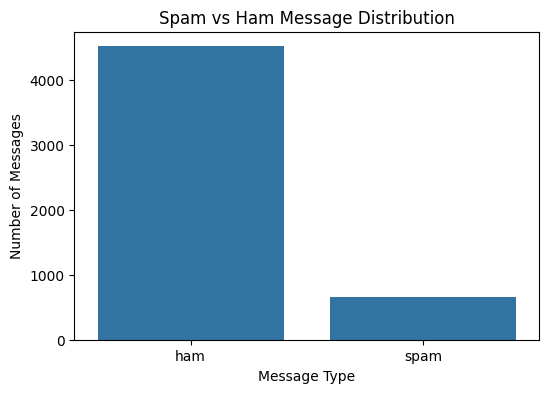

In [19]:
# Count Spam and Ham messages
print(df['label'].value_counts())

# Plot distribution
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='label')

plt.title('Spam vs Ham Message Distribution')
plt.xlabel('Message Type')
plt.ylabel('Number of Messages')

plt.show()

7. Analyze message length

                                             message  message_length
0  Go until jurong point, crazy.. Available only ...             111
1                      Ok lar... Joking wif u oni...              29
2  Free entry in 2 a wkly comp to win FA Cup fina...             155
3  U dun say so early hor... U c already then say...              49
4  Nah I don't think he goes to usf, he lives aro...              61


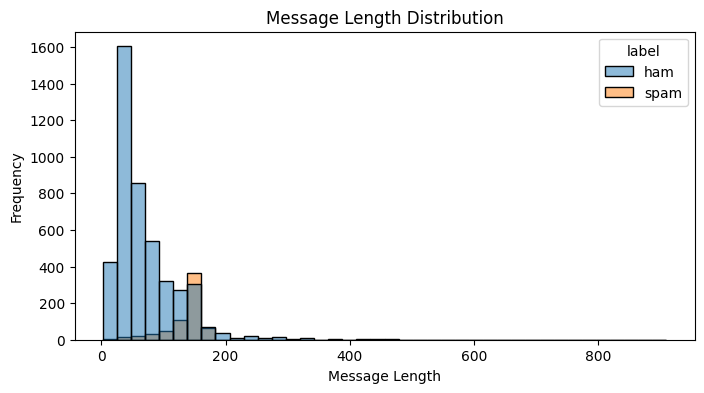

In [28]:
# Calculate message length
df['message_length'] = df['message'].apply(len)

# Display first five rows
print(df[['message', 'message_length']].head())

# Plot message length distribution
plt.figure(figsize=(8,4))

sns.histplot(data=df, x='message_length', hue='label', bins=40)

plt.title('Message Length Distribution')
plt.xlabel('Message Length')
plt.ylabel('Frequency')

plt.show()

8. Outlier detection

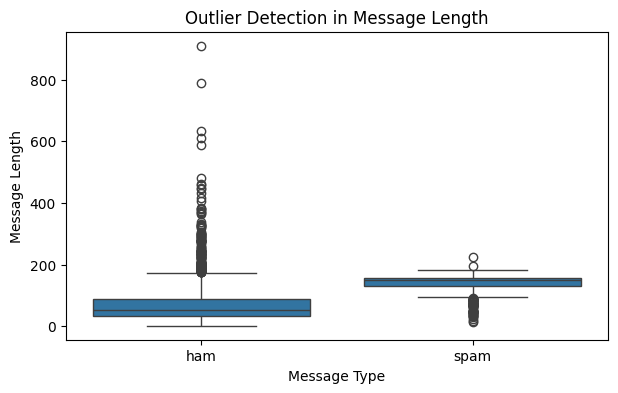

In [21]:
plt.figure(figsize=(7,4))

sns.boxplot(data=df, x='label', y='message_length')

plt.title('Outlier Detection in Message Length')
plt.xlabel('Message Type')
plt.ylabel('Message Length')

plt.show()

9. Correlation analysis

                message_length  word_count  label_numeric
message_length        1.000000    0.973667       0.384717
word_count            0.973667    1.000000       0.286576
label_numeric         0.384717    0.286576       1.000000


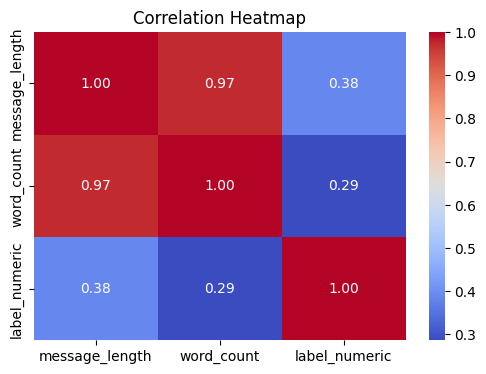

In [22]:
# Calculate word count
df['word_count'] = df['message'].apply(lambda x: len(x.split()))

# Convert labels into numerical values
df['label_numeric'] = df['label'].map({'ham': 0, 'spam': 1})

# Calculate correlation
correlation = df[['message_length', 'word_count', 'label_numeric']].corr()

print(correlation)

# Plot correlation heatmap
plt.figure(figsize=(6,4))

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

10. Feature Encoding using TF-IDF

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.model_selection import train_test_split

print("TF-IDF libraries imported successfully!")

TF-IDF libraries imported successfully!


In [30]:
# Input feature
X = df['message']

# Target variable
y = df['label'].map({'ham': 0, 'spam': 1})

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Input shape: (5169,)
Target shape: (5169,)

Target values:
label
0    4516
1     653
Name: count, dtype: int64


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 3618
Testing samples: 1551


In [32]:
# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=5000
)

# Fit on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (3618, 5000)
Testing data shape: (1551, 5000)


11. Implement Baseline Classification Models

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

print("All classification algorithms imported successfully!")

All classification algorithms imported successfully!


In [35]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [36]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_tfidf, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [37]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_tfidf, y_train)

print("KNN training completed!")

KNN training completed!


12. Evaluate the baseline models

In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


In [39]:
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "KNN": knn_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test_tfidf)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.9504     0.9917  0.6122    0.7571
1        Decision Tree    0.9568     0.8525  0.7959    0.8232
2                  KNN    0.9059     1.0000  0.2551    0.4065


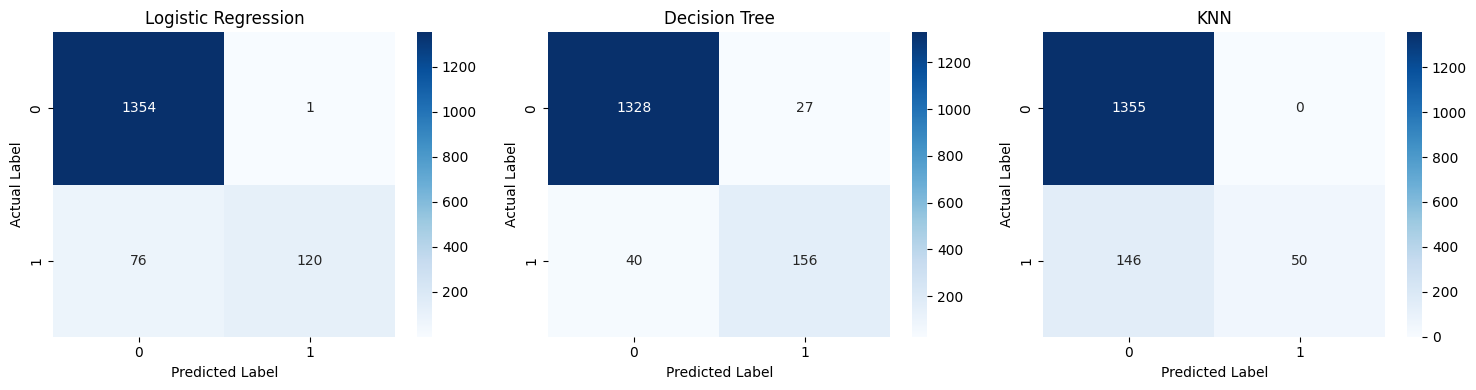

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):

    y_pred = model.predict(X_test_tfidf)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

13. Implement Random Forest Classifier

In [41]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [42]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train_tfidf, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [43]:
rf_pred = rf_model.predict(X_test_tfidf)

print("Random Forest Results")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=['Ham', 'Spam']
))

Random Forest Results
Accuracy: 0.9729206963249516
Precision: 0.9695121951219512
Recall: 0.8112244897959183
F1 Score: 0.8833333333333333

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98      1355
        Spam       0.97      0.81      0.88       196

    accuracy                           0.97      1551
   macro avg       0.97      0.90      0.93      1551
weighted avg       0.97      0.97      0.97      1551



14. Implement Gradient Boosting Classifier

In [44]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.utils.class_weight import compute_sample_weight

print("Gradient Boosting libraries imported successfully!")

Gradient Boosting libraries imported successfully!


In [45]:
svd = TruncatedSVD(n_components=100, random_state=42)

X_train_svd = svd.fit_transform(X_train_tfidf)
X_test_svd = svd.transform(X_test_tfidf)

print("Original features:", X_train_tfidf.shape[1])
print("Reduced features:", X_train_svd.shape[1])

Original features: 5000
Reduced features: 100


In [46]:
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Calculate balanced sample weights
sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

gb_model.fit(
    X_train_svd,
    y_train,
    sample_weight=sample_weights
)

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


In [47]:
gb_pred = gb_model.predict(X_test_svd)

print("Gradient Boosting Results")
print("Accuracy:", accuracy_score(y_test, gb_pred))
print("Precision:", precision_score(y_test, gb_pred))
print("Recall:", recall_score(y_test, gb_pred))
print("F1 Score:", f1_score(y_test, gb_pred))

Gradient Boosting Results
Accuracy: 0.961960025789813
Precision: 0.8215962441314554
Recall: 0.8928571428571429
F1 Score: 0.8557457212713936


15. Hyperparameter Tuning using GridSearchCV

In [48]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

print("GridSearchCV imported successfully!")

GridSearchCV imported successfully!


In [49]:
rf_parameters = {
    'n_estimators': [100, 200],
    'max_depth': [None, 20],
    'min_samples_split': [2, 5]
}

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_grid = GridSearchCV(
    RandomForestClassifier(
        random_state=42,
        class_weight='balanced'
    ),
    rf_parameters,
    cv=cv_strategy,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train_tfidf, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("Best Cross-validation F1 Score:")
print(rf_grid.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Random Forest Parameters:
{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}
Best Cross-validation F1 Score:
0.9210981692174368


In [50]:
best_rf = rf_grid.best_estimator_

print("Best Random Forest model selected!")

Best Random Forest model selected!


In [ ]:
gb_parameters = {
    'n_estimators': [100, 150],
    'learning_rate': [0.05, 0.1],
    'max_depth': [2, 3]
}

gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    gb_parameters,
    cv=cv_strategy,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

gb_grid.fit(
    X_train_svd,
    y_train,
    sample_weight=sample_weights
)

print("Best Gradient Boosting Parameters:")
print(gb_grid.best_params_)

print("Best Cross-validation F1 Score:")
print(gb_grid.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


In [52]:
best_gb = gb_grid.best_estimator_

print("Best Gradient Boosting model selected!")

Best Gradient Boosting model selected!


16. Cross-Validation

In [53]:
from sklearn.model_selection import cross_val_score

rf_cv_scores = cross_val_score(
    best_rf,
    X_train_tfidf,
    y_train,
    cv=cv_strategy,
    scoring='f1',
    n_jobs=-1
)

gb_cv_scores = cross_val_score(
    best_gb,
    X_train_svd,
    y_train,
    cv=cv_strategy,
    scoring='f1',
    n_jobs=-1
)

print("Random Forest CV Scores:", rf_cv_scores)
print("Random Forest Mean CV Score:", rf_cv_scores.mean())

print("\nGradient Boosting CV Scores:", gb_cv_scores)
print("Gradient Boosting Mean CV Score:", gb_cv_scores.mean())

Random Forest CV Scores: [0.94797688 0.91764706 0.91954023 0.90804598 0.9122807 ]
Random Forest Mean CV Score: 0.9210981692174368

Gradient Boosting CV Scores: [0.89772727 0.87356322 0.8839779  0.83977901 0.87058824]
Gradient Boosting Mean CV Score: 0.8731271264979086


17. ROC Curve and AUC Score

In [54]:
from sklearn.metrics import roc_curve, roc_auc_score

# Get prediction probabilities
rf_prob = best_rf.predict_proba(X_test_tfidf)[:, 1]
gb_prob = best_gb.predict_proba(X_test_svd)[:, 1]

# Calculate ROC values
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
gb_fpr, gb_tpr, _ = roc_curve(y_test, gb_prob)

# Calculate AUC
rf_auc = roc_auc_score(y_test, rf_prob)
gb_auc = roc_auc_score(y_test, gb_prob)

print("Random Forest AUC:", rf_auc)
print("Gradient Boosting AUC:", gb_auc)

Random Forest AUC: 0.9908671586715868
Gradient Boosting AUC: 0.985736877776941


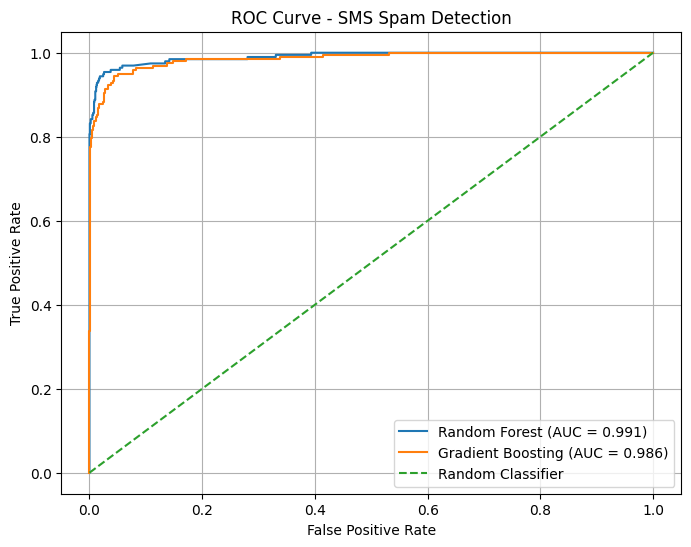

In [55]:
plt.figure(figsize=(8, 6))

plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.3f})')
plt.plot(gb_fpr, gb_tpr, label=f'Gradient Boosting (AUC = {gb_auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve - SMS Spam Detection')

plt.legend()
plt.grid()
plt.show()

In [56]:
final_models = {
    "Logistic Regression": (lr_model, X_test_tfidf),
    "Decision Tree": (dt_model, X_test_tfidf),
    "KNN": (knn_model, X_test_tfidf),
    "Tuned Random Forest": (best_rf, X_test_tfidf),
    "Tuned Gradient Boosting": (best_gb, X_test_svd)
}

final_results = []

for name, (model, test_data) in final_models.items():

    predictions = model.predict(test_data)

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

final_df = pd.DataFrame(final_results)

print(final_df.round(4))

                     Model  Accuracy  Precision  Recall  F1 Score
0      Logistic Regression    0.9504     0.9917  0.6122    0.7571
1            Decision Tree    0.9568     0.8525  0.7959    0.8232
2                      KNN    0.9059     1.0000  0.2551    0.4065
3      Tuned Random Forest    0.9755     0.9489  0.8520    0.8978
4  Tuned Gradient Boosting    0.9645     0.8473  0.8776    0.8622


18. Handle class imbalance

In [57]:
print("Class Distribution:")
print(df['label'].value_counts())

print("\nClass Percentages:")
print(df['label'].value_counts(normalize=True) * 100)

Class Distribution:
label
ham     4516
spam     653
Name: count, dtype: int64

Class Percentages:
label
ham     87.366996
spam    12.633004
Name: proportion, dtype: float64


19. Select the best-performing model

In [58]:
# Select model with highest F1 Score
best_model_name = final_df.loc[
    final_df['F1 Score'].idxmax(), 'Model'
]

print("Best Performing Model:", best_model_name)

print("\nModel Performance:")
print(final_df.sort_values(
    by='F1 Score',
    ascending=False
).round(4))

Best Performing Model: Tuned Random Forest

Model Performance:
                     Model  Accuracy  Precision  Recall  F1 Score
3      Tuned Random Forest    0.9755     0.9489  0.8520    0.8978
4  Tuned Gradient Boosting    0.9645     0.8473  0.8776    0.8622
1            Decision Tree    0.9568     0.8525  0.7959    0.8232
0      Logistic Regression    0.9504     0.9917  0.6122    0.7571
2                      KNN    0.9059     1.0000  0.2551    0.4065


20. Feature Importance Analysis

In [59]:
# Get feature names
feature_names = tfidf.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = lr_model.coef_[0]

# Create feature importance table
feature_importance = pd.DataFrame({
    'Word': feature_names,
    'Importance': coefficients
})

# Most important spam-related words
top_spam_words = feature_importance.sort_values(
    by='Importance',
    ascending=False
).head(15)

print(top_spam_words)

         Word  Importance
4723      txt    3.864076
3228   mobile    3.562128
4939      www    3.217240
827     claim    3.188665
4497     stop    3.063788
4204    reply    3.048502
1849     free    2.884166
4735       uk    2.839842
4605     text    2.713556
3965    prize    2.649010
4335  service    2.539496
3404      new    2.362620
4765   urgent    2.351665
900       com    2.350416
76       150p    2.324785


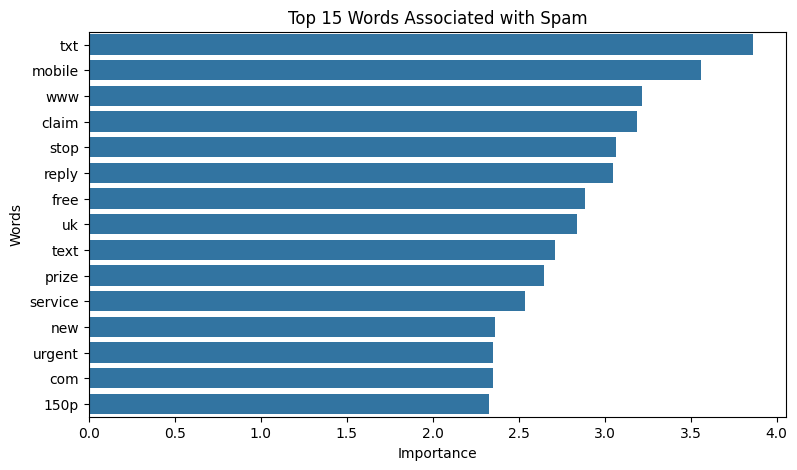

In [60]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=top_spam_words,
    x='Importance',
    y='Word'
)

plt.title('Top 15 Words Associated with Spam')
plt.xlabel('Importance')
plt.ylabel('Words')

plt.show()

21. Business Insights

In [62]:
print("BUSINESS INSIGHTS")

print("1. The model helps identify spam messages automatically.")
print("2. It can reduce unwanted and potentially misleading messages.")
print("3. Important words in messages help the model identify spam.")
print("4. The model can support safer SMS communication.")

BUSINESS INSIGHTS
1. The model helps identify spam messages automatically.
2. It can reduce unwanted and potentially misleading messages.
3. Important words in messages help the model identify spam.
4. The model can support safer SMS communication.
